# Problema de Inventario

Consideramos el problema de control de inventario con **ventas perdidas**:

$$
x_{t+1} = (x_t + a_t - e_{t+1})^+
$$

- $x_t$: inventario disponible al inicio del periodo $t$,
- $a_t$: cantidad pedida (acción de control),
- $e_{t+1}$: demanda, variables aleatorias i.i.d. con distribución **personalizable**,
- $(\,\cdot\,)^+ = \max(\,\cdot\,, 0)$: la demanda no satisfecha se pierde, no se acumula.

La ganancia en el periodo $t$ es

$$
r_t \;=\; \underbrace{p\,\min(e_{t+1},\; x_t + a_t)}_{\text{ventas}}
\;-\; \underbrace{c\, a_t}_{\text{costo del pedido}}
\;-\; \underbrace{\pi\,(e_{t+1} - x_t - a_t)^+}_{\text{penalización por faltante}}
$$

donde $p$ es el precio de venta, $c$ el costo unitario del producto solicitado y $\pi$ la
penalización por cada unidad de demanda que excede al inventario disponible $x_t + a_t$.

**Objetivo:** encontrar la política de pedidos $a_t = a(x_t)$ que maximiza la ganancia total
descontada $\mathbb{E}\big[\sum_{t\ge0} \gamma^t r_t\big]$.

---

## Reducción a "nivel de pedido" $y = x + a$

Definimos $y_t = x_t + a_t$ (inventario justo después de pedir). Como $a_t = y_t - x_t$, el costo
del pedido se separa:

$$
r_t = \big[p\,\mathbb{E}\min(e,y) - \pi\,\mathbb{E}(e-y)^+\big] - c\,(y - x)
      = R(y) - c\,y + c\,x
$$

y el estado siguiente solo depende de $y$: $x' = (y - e)^+$. La ecuación de Bellman queda

$$
V(x) = c\,x + \max_{y \ge x}\; G(y), \qquad
G(y) = R(y) - c\,y + \gamma\,\mathbb{E}\big[V\big((y-e)^+\big)\big].
$$

Basta un *máximo sufijo* sobre $G$ para evaluar el operador en todos los estados a la vez, y la
política óptima resulta de tipo **base-stock**: existe $S$ tal que $a^*(x) = (S - x)^+$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# Parámetros del problema
P_VENTA = 8.0     # p: ingreso por unidad vendida
C_PEDIDO = 5.0    # c: costo por unidad ordenada
PENAL   = 4.0     # pi: penalización por unidad de demanda no satisfecha
GAMMA   = 0.9     # factor de descuento
X_MAX   = 60      # capacidad máxima del almacén (cota de la rejilla de estados)


## Distribución de la demanda

La demanda $e_t$ puede ser cualquier variable aleatoria discreta con soporte finito
$\{0,1,\dots,K\}$ (una distribución continua se puede discretizar sobre la rejilla).
`hacer_demanda` regresa el soporte, la función de masa de probabilidad y un muestreador.
Opciones incluidas:

- `"poisson"`: `lam`
- `"binomial"`: `n`, `p`
- `"uniforme"`: `a`, `b` (enteros)
- `"geometrica"`: `p` (número de fallos antes del primer éxito)
- `"empirica"`: `valores`, un diccionario `{valor: probabilidad}` o una lista de observaciones


In [2]:
def hacer_demanda(tipo="poisson", **params):
    """Regresa (soporte, pmf, muestra) de la demanda e_t."""
    if tipo == "poisson":
        lam = params.get("lam", 15.0)
        K = int(np.ceil(lam + 8 * np.sqrt(lam)))   # cola despreciable
        q = np.empty(K + 1)
        q[0] = np.exp(-lam)
        for k in range(K):                          # recurrencia p_{k+1} = p_k * lam/(k+1)
            q[k + 1] = q[k] * lam / (k + 1)
    elif tipo == "binomial":
        n, prob = params["n"], params["p"]
        K = n
        q = np.empty(n + 1)
        q[0] = (1 - prob) ** n
        for k in range(n):
            q[k + 1] = q[k] * (n - k) / (k + 1) * prob / (1 - prob)
    elif tipo == "uniforme":
        a, b = params["a"], params["b"]
        K = b
        q = np.zeros(b + 1)
        q[a:b + 1] = 1.0 / (b - a + 1)
    elif tipo == "geometrica":
        prob = params["p"]
        K = int(np.ceil(np.log(1e-10) / np.log(1 - prob)))  # P(e > K) < 1e-10
        q = prob * (1 - prob) ** np.arange(K + 1)
    elif tipo == "empirica":
        datos = params["valores"]
        if isinstance(datos, dict):
            items = sorted(datos.items())
            sop = np.array([v for v, _ in items], dtype=int)
            pr = np.array([p for _, p in items], dtype=float)
            K = int(sop.max())
            q = np.zeros(K + 1)
            q[sop] = pr
        else:
            datos = np.asarray(datos, dtype=int)
            K = int(datos.max())
            q = np.bincount(datos, minlength=K + 1).astype(float)
    else:
        raise ValueError(f"Distribución desconocida: {tipo}")

    q = q / q.sum()
    soporte = np.arange(K + 1)

    def muestra(rng, n=1):
        return rng.choice(soporte, size=n, p=q)

    return soporte, q, muestra


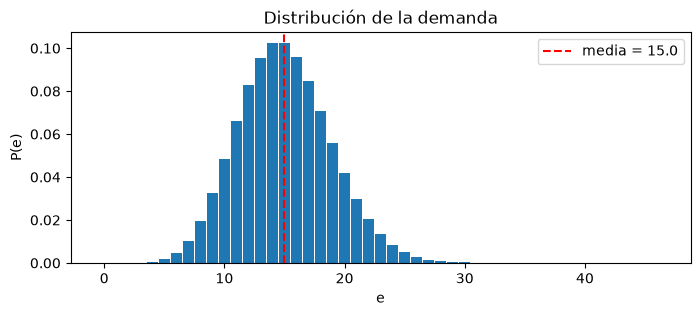

In [3]:
# Cambia aquí la distribución de la demanda
soporte, q, muestra = hacer_demanda("poisson", lam=15)

# Ejemplos equivalentes:
# soporte, q, muestra = hacer_demanda("uniforme", a=5, b=25)
# soporte, q, muestra = hacer_demanda("empirica", valores={10: 0.3, 15: 0.5, 20: 0.2})
# soporte, q, muestra = hacer_demanda("empirica", valores=[12, 15, 15, 18, 15, 21, 12])

media_e = float(soporte @ q)
cdf = np.cumsum(q)

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(soporte, q, width=0.9)
ax.axvline(media_e, color="red", ls="--", label=f"media = {media_e:.1f}")
ax.set(xlabel="e", ylabel="P(e)", title="Distribución de la demanda")
ax.legend()
plt.show()


## Recompensa esperada y matriz de transición

Para cada nivel posible $y \in \{0, \dots, X_{max}\}$ precalculamos

$$
s(y) = \mathbb{E}\min(e, y) = \sum_{e \le y} e\,q(e) + y\,P(e > y),
\qquad
u(y) = \mathbb{E}(e - y)^+ = \mathbb{E}[e] - s(y),
$$

con lo que $R(y) = p\,s(y) - \pi\,u(y)$. La matriz de transición $P_{y,x'} = P\big((y-e)^+ = x'\big)$ es

$$
P_{y,0} = P(e \ge y), \qquad P_{y,j} = q(y-j),\; j = 1, \dots, y.
$$


In [4]:
def tablas_esperadas(soporte, q, x_max):
    """s(y) = E[min(e,y)]  y  u(y) = E[(e-y)^+]  para y = 0..x_max."""
    e_q = soporte * q
    cdf = np.cumsum(q)
    K = len(q) - 1
    mu = e_q.sum()
    s = np.zeros(x_max + 1)
    for y in range(x_max + 1):
        m = min(y, K)
        s[y] = e_q[:m + 1].sum() + y * (1 - cdf[m])
    return s, mu - s


def matriz_transicion(q, x_max):
    """P[y, x'] = P( (y - e)^+ = x' )."""
    K = len(q) - 1
    cdf = np.cumsum(q)
    P = np.zeros((x_max + 1, x_max + 1))
    P[0, 0] = 1.0
    for y in range(1, x_max + 1):
        P[y, 0] = 1.0 - cdf[min(y - 1, K)]     # x' = 0  <=>  e >= y
        for j in range(max(1, y - K), y + 1):  # x' = y - e, con e <= K
            P[y, j] = q[y - j]
    return P


s_arr, u_arr = tablas_esperadas(soporte, q, X_MAX)
P = matriz_transicion(q, X_MAX)

assert np.allclose(P.sum(axis=1), 1), "Las filas de P deben sumar 1"


## Iteración de valor

Aplicamos el operador de Bellman hasta convergencia. Es una contracción de módulo $\gamma$
en norma supremo, así que el punto fijo es único:

$$
V_{n+1}(x) = c\,x + \max_{y \ge x} G_n(y), \qquad
G_n(y) = R(y) - c\,y + \gamma\,(P V_n)(y).
$$

El máximo sobre $y \ge x$ es un *máximo sufijo* de $G_n$: un solo barrido de derecha a
izquierda actualiza todos los estados.


In [5]:
def iteracion_valor(s_arr, u_arr, P, p, c, pen, gamma, tol=1e-9, max_it=100_000):
    yv = np.arange(len(s_arr))
    R = p * s_arr - pen * u_arr
    V = np.zeros(len(s_arr))
    for it in range(max_it):
        G = R - c * yv + gamma * (P @ V)
        suf = np.maximum.accumulate(G[::-1])[::-1]   # suf[x] = max_{y >= x} G(y)
        V_new = c * yv + suf
        delta = np.abs(V_new - V).max()
        V = V_new
        if delta < tol:
            return V, G, it
    return V, G, max_it


V, G, n_it = iteracion_valor(s_arr, u_arr, P, P_VENTA, C_PEDIDO, PENAL, GAMMA)
print(f"Convergencia en {n_it} iteraciones")


Convergencia en 233 iteraciones


Nivel base-stock óptimo: S = 21


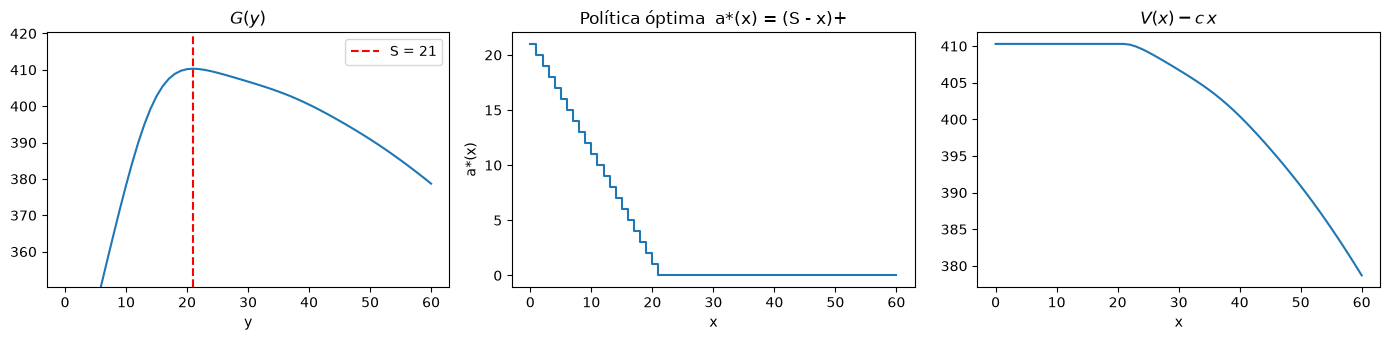

In [6]:
# Política óptima: y*(x) = argmax_{y >= x} G(y),  a*(x) = y*(x) - x
xg = np.arange(X_MAX + 1)
suf = np.maximum.accumulate(G[::-1])[::-1]
y_opt = np.array([x + np.argmax(G[x:] >= suf[x] - 1e-9) for x in xg])
a_opt = y_opt - xg
S = int(np.argmax(G))
print(f"Nivel base-stock óptimo: S = {S}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(xg, G)
axes[0].axvline(S, color="red", ls="--", label=f"S = {S}")
axes[0].set(xlabel="y", title="$G(y)$", ylim=(G.max() - 60, G.max() + 10))
axes[0].legend()
axes[1].step(xg, a_opt, where="post")
axes[1].set(xlabel="x", ylabel="a*(x)", title="Política óptima  a*(x) = (S - x)+")
axes[2].plot(xg, V - C_PEDIDO * xg)
axes[2].set(xlabel="x", title=r"$V(x) - c\,x$")
plt.tight_layout()
plt.show()


## Simulación de trayectorias

Simulamos el sistema $x_{t+1} = (x_t + a_t - e_{t+1})^+$ bajo la política óptima.


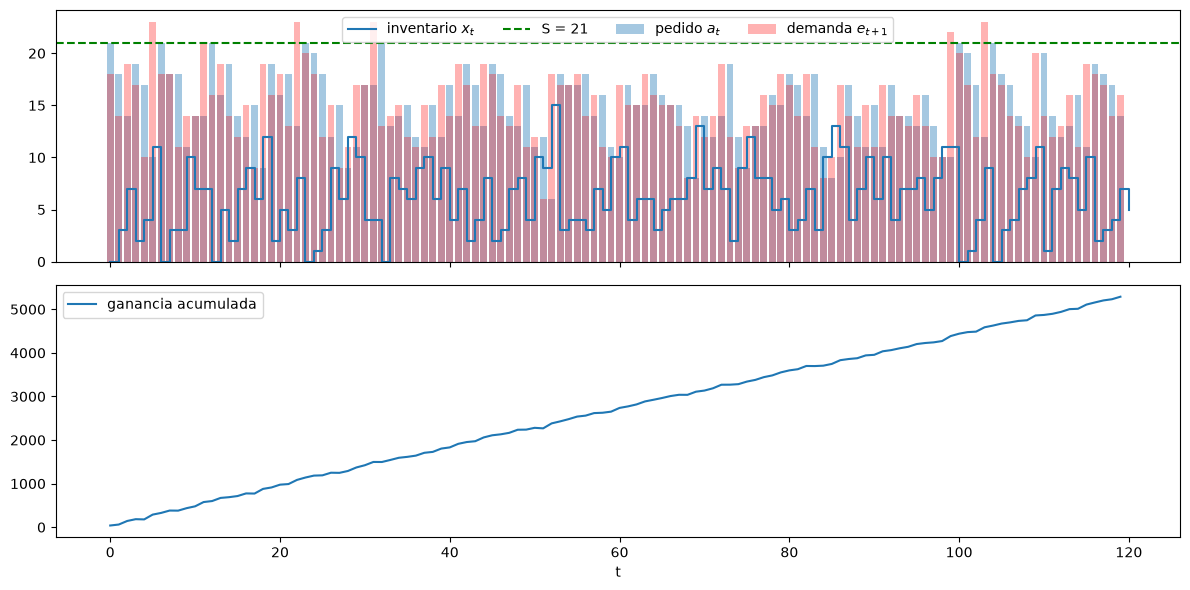

In [7]:
def simular(a_fun, x0, T, rng):
    """Trayectoria del inventario bajo la política a = a_fun(x)."""
    xs, accs, dem, gan = np.zeros(T + 1), np.zeros(T), np.zeros(T), np.zeros(T)
    x = x0
    for t in range(T):
        a = a_fun(int(min(x, X_MAX)))
        e = muestra(rng)[0]
        xs[t], accs[t], dem[t] = x, a, e
        gan[t] = (P_VENTA * min(e, x + a)        # ventas
                  - C_PEDIDO * a                  # costo del pedido
                  - PENAL * max(e - (x + a), 0))  # penalización por faltante
        x = max(x + a - e, 0)
    xs[T] = x
    return xs, accs, dem, gan


T = 120
xs, accs, dem, gan = simular(lambda x: a_opt[x], x0=0, T=T, rng=rng)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].step(range(T + 1), xs, where="post", label="inventario $x_t$")
axes[0].bar(range(T), accs, alpha=0.4, label="pedido $a_t$")
axes[0].bar(range(T), dem, alpha=0.3, color="red", label="demanda $e_{t+1}$")
axes[0].axhline(S, color="green", ls="--", label=f"S = {S}")
axes[0].legend(ncol=4)
axes[1].plot(np.cumsum(gan), label="ganancia acumulada")
axes[1].set(xlabel="t")
axes[1].legend()
plt.tight_layout()
plt.show()


## Comparación contra políticas ingenuas

Evaluamos por Monte Carlo la ganancia total en $T = 365$ periodos:
- **óptima**: $a^*(x) = (S - x)^+$,
- **sin pedidos**: nunca se repone inventario,
- **hasta la media**: se pide lo necesario para llegar a $\mathbb{E}[e]$.


          óptima: ganancia media =   16077.3   (sd =   196.2)


     sin pedidos: ganancia media =  -21922.9   (sd =   295.8)


  hasta la media: ganancia media =   13056.1   (sd =   156.8)


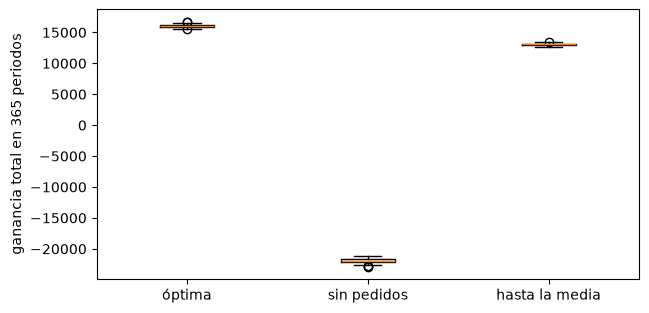

In [8]:
politicas = {
    "óptima":        lambda x: a_opt[x],
    "sin pedidos":   lambda x: 0,
    "hasta la media": lambda x: max(0.0, media_e - x),
}

M, T = 300, 365
resultados = {}
for nombre, pol in politicas.items():
    tot = np.array([
        simular(pol, x0=0, T=T, rng=np.random.default_rng(m))[3].sum()
        for m in range(M)
    ])
    resultados[nombre] = tot
    print(f"{nombre:>16}: ganancia media = {tot.mean():9.1f}   (sd = {tot.std():7.1f})")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.boxplot(resultados.values(), tick_labels=resultados.keys())
ax.set_ylabel("ganancia total en 365 periodos")
plt.show()


## Sensibilidad del nivel óptimo $S$

El nivel base-stock óptimo crece cuando el faltante es más costoso (mayor $\pi$) o cuando
crece la demanda esperada.


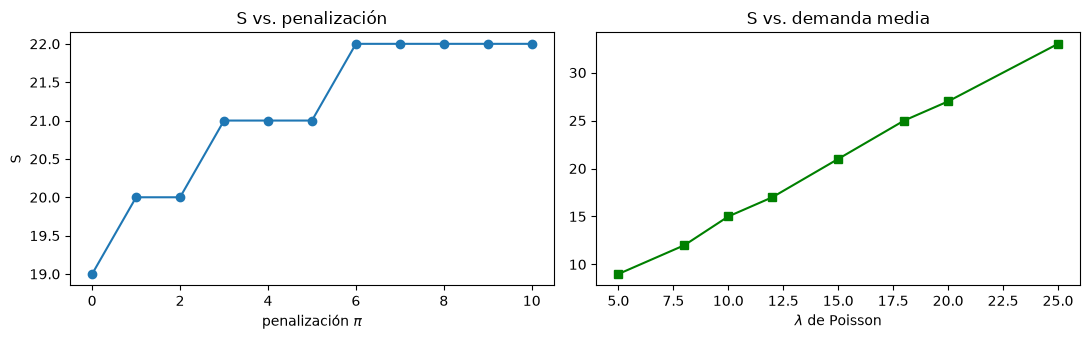

In [9]:
pen_grid = np.linspace(0, 10, 11)
S_pen = [int(np.argmax(iteracion_valor(s_arr, u_arr, P, P_VENTA, C_PEDIDO, pen, GAMMA)[1]))
         for pen in pen_grid]

lam_grid = [5, 8, 10, 12, 15, 18, 20, 25]
S_lam = []
for lam in lam_grid:
    sop_l, q_l, _ = hacer_demanda("poisson", lam=lam)
    s_l, u_l = tablas_esperadas(sop_l, q_l, X_MAX)
    P_l = matriz_transicion(q_l, X_MAX)
    S_lam.append(int(np.argmax(iteracion_valor(s_l, u_l, P_l, P_VENTA, C_PEDIDO, PENAL, GAMMA)[1])))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(pen_grid, S_pen, "o-")
axes[0].set(xlabel=r"penalización $\pi$", ylabel="S", title="S vs. penalización")
axes[1].plot(lam_grid, S_lam, "s-", color="green")
axes[1].set(xlabel=r"$\lambda$ de Poisson", title="S vs. demanda media")
plt.tight_layout()
plt.show()


## Aproximación de la política con una red neuronal

La política óptima $a^*(x) = (S - x)^+$ es una función continua por tramos: un buen banco de
pruebas para el **teorema de aproximación universal**. Usamos una suma de sigmoides

$$
\hat{a}(x) = \sum_{i=1}^{N} c_i\,\sigma(w_i x + b_i)
$$

entrenada por descenso de gradiente sobre el error cuadrático contra la política óptima,
con las rutinas del paquete `neuralnetworks` de este repositorio.


MSE final: 1.59e-04


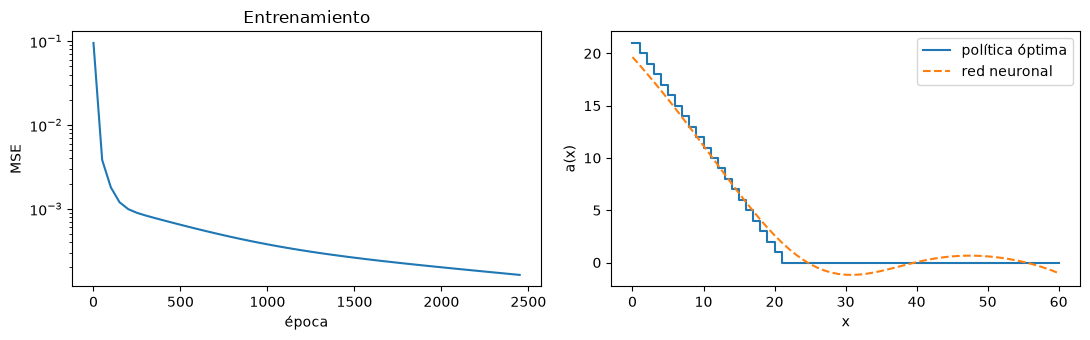

In [10]:
import sys
sys.path.append("..")

from neuralnetworks.nn import activation
from neuralnetworks.maths import gradient

N = 5                                   # número de neuronas
xn = xg / X_MAX                         # entrada normalizada a [0, 1]
an = a_opt / X_MAX                      # objetivo normalizado

def red(x, theta):
    C, W, B = theta[:N], theta[N:2 * N], theta[2 * N:3 * N]
    return activation(np.outer(x, W) + B) @ C

def mse(theta):
    return np.mean((red(xn, theta) - an) ** 2)

theta = np.concatenate([rng.normal(0, 1, N), rng.normal(0, 5, N), rng.normal(0, 5, N)])

lr, epochs = 0.5, 2500
historia = []
for ep in range(epochs):
    theta = theta - lr * gradient(mse, theta)
    if ep % 50 == 0:
        historia.append(mse(theta))
print(f"MSE final: {mse(theta):.2e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].semilogy(np.arange(0, epochs, 50), historia)
axes[0].set(xlabel="época", ylabel="MSE", title="Entrenamiento")
axes[1].step(xg, a_opt, where="post", label="política óptima")
axes[1].plot(xg, red(xn, theta) * X_MAX, "--", label="red neuronal")
axes[1].set(xlabel="x", ylabel="a(x)")
axes[1].legend()
plt.tight_layout()
plt.show()


## Conclusiones

- Con $y_t = x_t + a_t$ el problema se reduce a maximizar un *máximo sufijo* de
  $G(y) = R(y) - c\,y + \gamma\,\mathbb{E}V((y-e)^+)$, lo que hace la iteración de
  valor muy eficiente.
- La política óptima es de **base-stock**: pedir $(S - x)^+$ con $S = \arg\max G$.
- $S$ aumenta con la penalización $\pi$ y con la demanda esperada.
- Para cambiar el problema basta modificar los parámetros y la distribución en
  `hacer_demanda` (incluida una opción empírica a partir de datos observados).
- La política óptima obtenida puede aproximarse con una red neuronal pequeña de
  sigmoides, ilustrando el teorema de aproximación universal.
